# 01 — HOI4D Dataset Statistics (DataLoader-Only)

This notebook computes comprehensive dataset statistics for **HOI4D** using **exclusively the unified PyTorch `DataLoader`** (`EgoClipDataset.from_config` + `torch.utils.data.DataLoader`). No raw dataset files, index JSONLs, or adapters are accessed directly.

### What HOI4D provides through `DataLoader`
- **3D Ground Truth:** calibrated intrinsics (`K`), camera trajectory (`T_world_cam`), 21-joint 3D/2D MANO hand pose (`hand_joints_3d`, `hand_joints_2d`, `hand_mano`), 6-DoF object/part poses (`obj_T_cam_obj`, `obj_dims`, `obj_bbox_2d`), and derived 3D hand–object contact (`contact`, `contact_dist`).
- **Dense & 3D Modalities:** RGB frames (`frames`), pixel-aligned metric depth (`depth`), 2D instance masks (`seg`), static world-frame scene point clouds (`scene_points`), and CAD surface point clouds (`object_points`).
- **Action Labels:** frame-aligned action segment labels (`action`).

### Two-Pass DataLoader Strategy
1. **Pass 1 — Broad Annotation & 3D Geometry `DataLoader`** (`modalities=["contact"]`, native resolution, sliding windows across the full 20 s timeline): fast scan without video decoding to measure category/subject/device coverage, modality validity, action labels, 3D hand/object geometry, motion speeds, camera motion, and contact statistics.
2. **Pass 2 — Dense Multimodal `DataLoader`** (`modalities=["rgb", "depth", "seg", "scene", "mesh", "contact"]`, `256×256` training transform): analyzes RGB, metric depth, segmentation class occupancy, 3D scene/CAD point clouds, and renders visual overlays directly from batch tensors.

In [1]:
import time
import warnings
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Subset

from robot.data.schema import HAND_PARENTS
from robot.data.torch_dataset import EgoClipDataset

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# --- Notebook Configuration (adjust to scale up to 100% full scan) ---
SEED = 42
PASS1_MAX_CLIPS = 1200   # Set to None to iterate ALL sliding-window clips
PASS2_MAX_CLIPS = 96     # Dense RGB + Depth + Seg + Scene + Mesh clips
BATCH_SIZE_P1 = 32
BATCH_SIZE_P2 = 8
NUM_WORKERS = 8

# HOI4D category code -> name mapping (from sequence_id token C#)
HOI4D_CATEGORIES = {
    "C1": "ToyCar", "C2": "Mug", "C3": "Laptop", "C4": "StorageFurniture",
    "C5": "Bottle", "C6": "Safe", "C7": "Bowl", "C8": "Bucket",
    "C9": "Scissors", "C11": "Pliers", "C12": "Kettle", "C13": "Knife",
    "C14": "TrashCan", "C17": "Lamp", "C18": "Stapler", "C20": "Chair",
}
HOI4D_RIGID = {"ToyCar", "Mug", "Bottle", "Bowl", "Kettle", "Knife"}

def parse_hoi4d_id(seq_id: str) -> dict:
    parts = seq_id.split("-")
    cat_code = parts[2] if len(parts) > 2 else "Unknown"
    cat_name = HOI4D_CATEGORIES.get(cat_code, cat_code)
    return {
        "device": parts[0] if len(parts) > 0 else "Unknown",
        "human": parts[1] if len(parts) > 1 else "Unknown",
        "cat_code": cat_code,
        "category": cat_name,
        "rigid": cat_name in HOI4D_RIGID,
        "instance": parts[3] if len(parts) > 3 else "Unknown",
        "scene": parts[4] if len(parts) > 4 else "Unknown",
        "layout": parts[5] if len(parts) > 5 else "Unknown",
        "task": parts[6] if len(parts) > 6 else "Unknown",
    }

def make_loader(cfg: dict, max_clips: int | None, batch_size: int, seed: int = SEED) -> tuple[DataLoader, int]:
    ds = EgoClipDataset.from_config(cfg)
    total = len(ds)
    if max_clips is not None and total > max_clips:
        rng = np.random.default_rng(seed)
        idx = np.sort(rng.choice(total, size=max_clips, replace=False)).tolist()
        ds_view = Subset(ds, idx)
    else:
        ds_view = ds
    dl = DataLoader(ds_view, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS)
    return dl, total

print("Setup complete. PyTorch:", torch.__version__)

ModuleNotFoundError: No module named 'matplotlib'

## 1. Pass 1 — Broad Annotation, 3D Pose, Motion & Contact Scan via `DataLoader`

We sample 16-frame clips at native **15 fps** with `stride_s = 5.0` across all HOI4D sequences so clips span the beginning, middle, and end of each 20-second recording (`0 s, 5 s, 10 s, 15 s`). No image transforms are applied in Pass 1 so `K`, `hand_joints_2d`, and `obj_bbox_2d` remain in native `1920×1080` pixels.

In [ ]:
cfg_pass1 = {
    "clip_len": 16,
    "fps": 15,
    "max_objects": 6,
    "modalities": ["contact"],
    "sources": [
        {
            "dataset": "hoi4d",
            "sampling": "sliding",
            "stride_s": 5.0,
        }
    ],
}

t0 = time.time()
dl_p1, total_windows_p1 = make_loader(cfg_pass1, PASS1_MAX_CLIPS, BATCH_SIZE_P1)
print(f"Pass 1 DataLoader ready in {time.time() - t0:.2f}s | total available clips: {total_windows_p1:,} | iterating: {len(dl_p1.dataset):,}")

# Accumulators populated purely from DataLoader batches
seq_seen = set()
clip_rows = []
action_counter = Counter()
action_contact = defaultdict(lambda: [0, 0])  # [in_contact_frames, valid_frames]

hand_wrist_3d = {"left": [], "right": []}
hand_wrist_2d = {"left": [], "right": []}
hand_speed_3d = {"left": [], "right": []}
hand_accel_3d = {"left": [], "right": []}
mano_betas_list = []
mano_pose_norm_list = []

obj_dims_rows = []
obj_dist_list = []
obj_z_list = []
obj_area_frac_list = []
obj_aspect_list = []

contact_dist_list = []
cam_lin_speed = []
cam_ang_speed = []
intrinsics_rows = []
dt_list = []

t_scan = time.time()
for batch in dl_p1:
    B, T = batch["timestamps"].shape
    ts = batch["timestamps"].numpy()           # (B, T)
    fi = batch["frame_indices"].numpy()        # (B, T)
    K = batch["K"].numpy()                     # (B, 3, 3)
    K_valid = batch["K_valid"].numpy()         # (B,)

    hv = batch["hand_valid"].numpy()           # (B, 2, T)
    h3d = batch["hand_joints_3d"].numpy()      # (B, 2, T, 21, 3)
    h3d_v = batch["hand_joints_3d_valid"].numpy()
    h2d = batch["hand_joints_2d"].numpy()      # (B, 2, T, 21, 2)
    hmano = batch["hand_mano"].numpy()         # (B, 2, T, 61)

    ov = batch["obj_valid"].numpy()            # (B, O, T)
    opv = batch["obj_pose_valid"].numpy()      # (B, O, T)
    oT = batch["obj_T_cam_obj"].numpy()        # (B, O, T, 4, 4)
    obox = batch["obj_bbox_2d"].numpy()        # (B, O, T, 4)
    odims = batch["obj_dims"].numpy()          # (B, O, 3)

    cv = batch["cam_valid"].numpy()            # (B, T)
    Twc = batch["T_world_cam"].numpy()         # (B, T, 4, 4)

    ct = batch["contact"].numpy()              # (B, 2, O, T)
    cdist = batch["contact_dist"].numpy()      # (B, 2, O, T)
    cval = batch["contact_valid"].numpy()      # (B, 2, O, T)

    dt = np.diff(ts, axis=1)                   # (B, T-1)
    dt_list.append(dt.ravel())

    for b in range(B):
        sid = batch["sequence_id"][b]
        seq_seen.add(sid)
        info = parse_hoi4d_id(sid)
        act = batch["action"][b] or "(none)"
        action_counter[act] += 1

        # Hand frame counts
        left_f = int(hv[b, 0].sum())
        right_f = int(hv[b, 1].sum())
        both_f = int((hv[b, 0] & hv[b, 1]).sum())
        any_h_f = int((hv[b, 0] | hv[b, 1]).sum())

        # Contact frames (any hand-object pair per frame)
        c_any_valid = cval[b].any(axis=(0, 1))  # (T,)
        c_any_hit = (ct[b] & cval[b]).any(axis=(0, 1))
        action_contact[act][0] += int(c_any_hit.sum())
        action_contact[act][1] += int(c_any_valid.sum())

        n_objs_clip = int(ov[b].any(axis=1).sum())
        clip_rows.append({
            "sequence_id": sid,
            **info,
            "start_s": float(ts[b, 0]),
            "end_s": float(ts[b, -1]),
            "K_valid": bool(K_valid[b]),
            "cam_valid_frac": float(cv[b].mean()),
            "left_hand_frac": left_f / T,
            "right_hand_frac": right_f / T,
            "bimanual_frac": both_f / T,
            "any_hand_frac": any_h_f / T,
            "hand_3d_frac": float(h3d_v[b].any(axis=0).mean()),
            "n_objects": n_objs_clip,
            "obj_pose_frac": float(opv[b].any(axis=0).mean()),
            "contact_valid_frac": float(c_any_valid.mean()),
            "contact_hit_frac": float(c_any_hit.sum() / max(int(c_any_valid.sum()), 1)) if c_any_valid.any() else np.nan,
            "action": act,
        })

        if K_valid[b]:
            intrinsics_rows.append({
                "device": info["device"],
                "fx": float(K[b, 0, 0]), "fy": float(K[b, 1, 1]),
                "cx": float(K[b, 0, 2]), "cy": float(K[b, 1, 2]),
            })

        # 3D & 2D hand wrist + kinematics + MANO
        for s_idx, side in enumerate(("left", "right")):
            m = h3d_v[b, s_idx]
            if m.any():
                w3 = h3d[b, s_idx, :, 0, :]  # (T, 3) wrist
                w2 = h2d[b, s_idx, :, 0, :]  # (T, 2)
                hand_wrist_3d[side].append(w3[m])
                hand_wrist_2d[side].append(w2[m])
                mano_betas_list.append(hmano[b, s_idx, m, 48:58])
                mano_pose_norm_list.append(np.linalg.norm(hmano[b, s_idx, m, 3:48], axis=-1))
                # Consecutive frame velocity & acceleration
                pair_m = m[:-1] & m[1:] & (dt[b] > 1e-4)
                if pair_m.any():
                    vel = np.linalg.norm(np.diff(w3, axis=0), axis=-1) / np.maximum(dt[b], 1e-4)
                    hand_speed_3d[side].append(vel[pair_m])
                tri_m = m[:-2] & m[1:-1] & m[2:] & (dt[b, :-1] > 1e-4) & (dt[b, 1:] > 1e-4)
                if tri_m.any():
                    dt_mid = 0.5 * (dt[b, :-1] + dt[b, 1:])
                    acc = np.linalg.norm(w3[2:] - 2 * w3[1:-1] + w3[:-2], axis=-1) / (dt_mid ** 2)
                    hand_accel_3d[side].append(acc[tri_m])

        # Object geometry & poses
        for o in range(ov.shape[1]):
            if not ov[b, o].any():
                continue
            dims = odims[b, o]
            if np.all(dims > 0):
                obj_dims_rows.append({
                    "category": info["category"], "rigid": info["rigid"],
                    "l": float(dims[0]), "w": float(dims[1]), "h": float(dims[2]),
                    "vol_L": float(dims[0] * dims[1] * dims[2] * 1000.0),
                })
            om = opv[b, o]
            if om.any():
                pos = oT[b, o, om, :3, 3]
                obj_dist_list.append(np.linalg.norm(pos, axis=-1))
                obj_z_list.append(pos[:, 2])
            bm = ov[b, o]
            if bm.any():
                bb = obox[b, o, bm]
                bw = np.maximum(bb[:, 2] - bb[:, 0], 0.0)
                bh = np.maximum(bb[:, 3] - bb[:, 1], 0.0)
                valid_bb = (bw > 1.0) & (bh > 1.0)
                if valid_bb.any():
                    obj_area_frac_list.append((bw[valid_bb] * bh[valid_bb]) / (1920.0 * 1080.0))
                    obj_aspect_list.append(bw[valid_bb] / bh[valid_bb])

        # Contact distances
        if cval[b].any():
            contact_dist_list.append(cdist[b][cval[b]])

        # Camera linear & angular speed
        cm = cv[b, :-1] & cv[b, 1:] & (dt[b] > 1e-4)
        if cm.any():
            dp = np.linalg.norm(np.diff(Twc[b, :, :3, 3], axis=0), axis=-1) / np.maximum(dt[b], 1e-4)
            cam_lin_speed.append(dp[cm])
            R0 = Twc[b, :-1, :3, :3][cm]
            R1 = Twc[b, 1:, :3, :3][cm]
            Rrel = np.matmul(np.transpose(R0, (0, 2, 1)), R1)
            tr = np.clip((np.trace(Rrel, axis1=1, axis2=2) - 1.0) * 0.5, -1.0, 1.0)
            ang = np.degrees(np.arccos(tr)) / np.maximum(dt[b][cm], 1e-4)
            cam_ang_speed.append(ang)

df = pd.DataFrame(clip_rows)
print(f"Pass 1 completed in {time.time() - t_scan:.2f}s | {len(df):,} clips across {len(seq_seen):,} unique sequences")

Pass 1 DataLoader ready in 0.10s | total available clips: 11,892 | iterating: 1,200


Pass 1 completed in 32.57s | 1,200 clips across 1,038 unique sequences


## 2. Dataset Coverage, Hierarchy & Modality Validity

,Metric,Value
0,Total sliding-window clips in DataLoader,"11,892"
1,Clips analyzed in Pass 1,"1,200"
2,Unique sequences covered,"1,038"
3,Unique categories / devices / humans,16 / 4 / 4
4,Unique scenes / tasks,258 / 6
5,Rigid vs. Articulated clips,490 (40.8%) vs. 710 (59.2%)
6,Median frame step dt (effective fps),66.67 ms (15.00 fps)
7,Intrinsics K_valid rate,100.00%
8,Camera pose cam_valid frame rate,100.00%
9,Object 6-DoF pose frame rate,100.00%


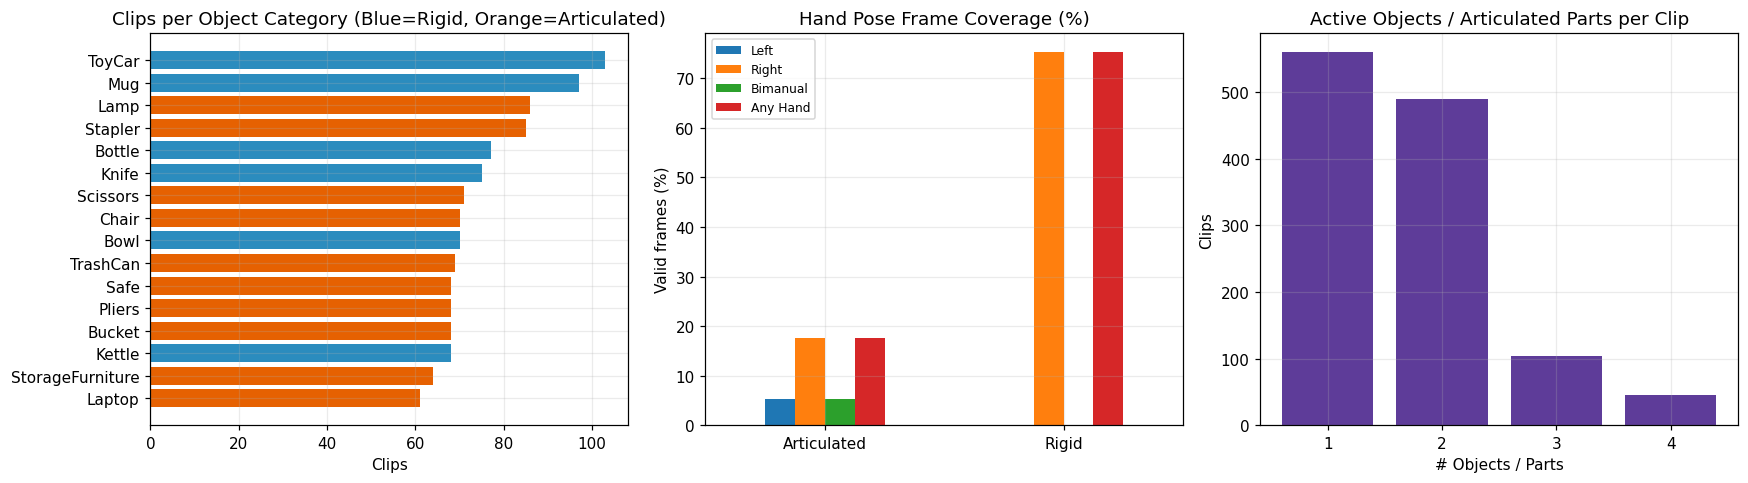

In [ ]:
dt_all = np.concatenate(dt_list)
summary = pd.DataFrame([
    ("Total sliding-window clips in DataLoader", f"{total_windows_p1:,}"),
    ("Clips analyzed in Pass 1", f"{len(df):,}"),
    ("Unique sequences covered", f"{df['sequence_id'].nunique():,}"),
    ("Unique categories / devices / humans", f"{df['category'].nunique()} / {df['device'].nunique()} / {df['human'].nunique()}"),
    ("Unique scenes / tasks", f"{df['scene'].nunique()} / {df['task'].nunique()}"),
    ("Rigid vs. Articulated clips", f"{df['rigid'].sum():,} ({df['rigid'].mean()*100:.1f}%) vs. {(~df['rigid']).sum():,} ({(~df['rigid']).mean()*100:.1f}%)"),
    ("Median frame step dt (effective fps)", f"{np.median(dt_all)*1000:.2f} ms ({1.0/np.median(dt_all):.2f} fps)"),
    ("Intrinsics K_valid rate", f"{df['K_valid'].mean()*100:.2f}%"),
    ("Camera pose cam_valid frame rate", f"{df['cam_valid_frac'].mean()*100:.2f}%"),
    ("Object 6-DoF pose frame rate", f"{df['obj_pose_frac'].mean()*100:.2f}%"),
    ("Any hand 3D pose frame rate", f"{df['hand_3d_frac'].mean()*100:.2f}%"),
    ("Left / Right / Bimanual hand frame rate", f"{df['left_hand_frac'].mean()*100:.1f}% / {df['right_hand_frac'].mean()*100:.1f}% / {df['bimanual_frac'].mean()*100:.1f}%"),
    ("Clips with valid contact proxy", f"{(df['contact_valid_frac'] > 0).mean()*100:.1f}%"),
    ("Mean contact rate (given valid hand+obj)", f"{df['contact_hit_frac'].mean()*100:.1f}%"),
], columns=["Metric", "Value"])
display(summary)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Category counts colored by Rigid vs Articulated
cat_df = df.groupby(["category", "rigid"]).size().reset_index(name="clips").sort_values("clips", ascending=True)
colors = ["#2b8cbe" if r else "#e66101" for r in cat_df["rigid"]]
axes[0].barh(cat_df["category"], cat_df["clips"], color=colors)
axes[0].set_title("Clips per Object Category (Blue=Rigid, Orange=Articulated)")
axes[0].set_xlabel("Clips")

# Hand availability by Rigid vs Articulated
hand_grp = df.groupby("rigid")[["left_hand_frac", "right_hand_frac", "bimanual_frac", "any_hand_frac"]].mean() * 100
hand_grp.index = ["Articulated", "Rigid"]
hand_grp.plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Hand Pose Frame Coverage (%)")
axes[1].set_ylabel("Valid frames (%)")
axes[1].legend(["Left", "Right", "Bimanual", "Any Hand"], fontsize=8)

# Active objects / parts per clip
obj_cnt = df["n_objects"].value_counts().sort_index()
axes[2].bar(obj_cnt.index.astype(str), obj_cnt.values, color="#5e3c99")
axes[2].set_title("Active Objects / Articulated Parts per Clip")
axes[2].set_xlabel("# Objects / Parts")
axes[2].set_ylabel("Clips")

plt.tight_layout()
plt.show()

## 3. Action Label Distribution & Contact Rate by Action

,action,clips,share_%,contact_valid_frames,contact_rate_%
0,rest,333,27.750000,385,11.688312
1,putdown,201,16.750000,1872,98.450855
2,Reachout,185,15.416667,1427,20.812894
3,carry,176,14.666667,1472,99.932065
4,Stop,84,7.000000,649,80.277350
5,Pickup,48,4.000000,512,91.406250
6,close,47,3.916667,256,98.046875
7,Grasp,38,3.166667,304,86.513158
8,open,22,1.833333,208,100.000000
9,(none),20,1.666667,288,75.000000


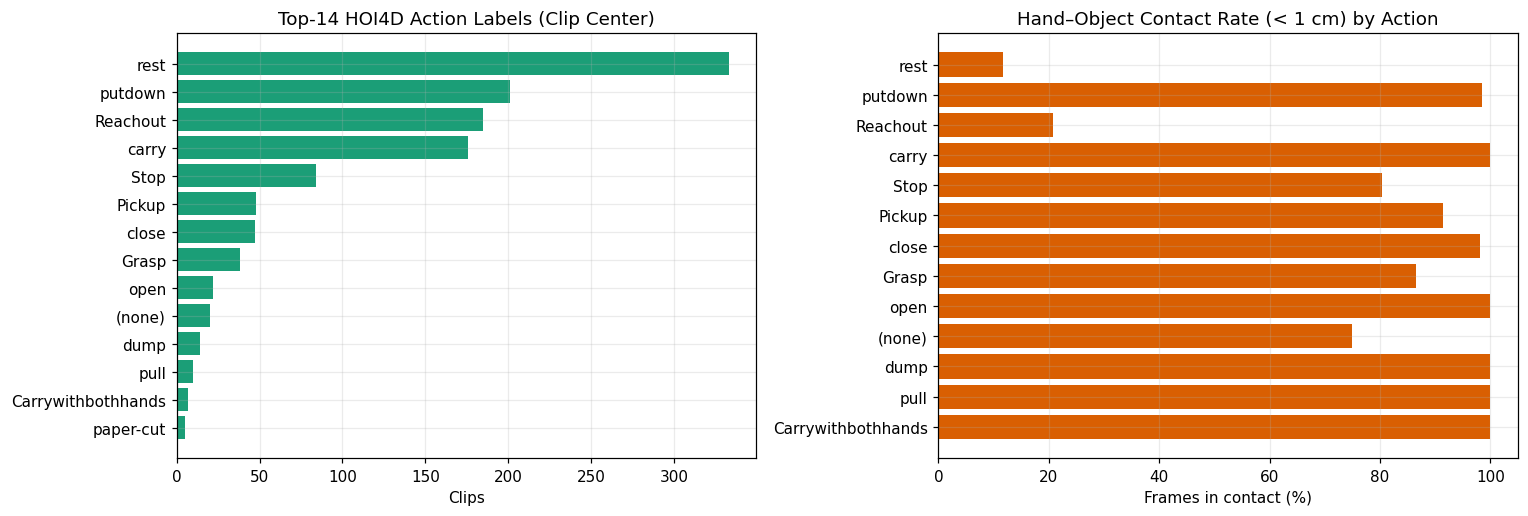

In [ ]:
act_rows = []
for act, cnt in action_counter.most_common():
    hit, tot = action_contact[act]
    act_rows.append({
        "action": act,
        "clips": cnt,
        "share_%": 100.0 * cnt / len(df),
        "contact_valid_frames": tot,
        "contact_rate_%": (100.0 * hit / tot) if tot > 0 else np.nan,
    })
act_df = pd.DataFrame(act_rows)
display(act_df.head(15))

top_act = act_df.head(14).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].barh(top_act["action"], top_act["clips"], color="#1b9e77")
axes[0].set_title("Top-14 HOI4D Action Labels (Clip Center)")
axes[0].set_xlabel("Clips")

top_c = top_act.dropna(subset=["contact_rate_%"])
axes[1].barh(top_c["action"], top_c["contact_rate_%"], color="#d95f02")
axes[1].set_xlim(0, 105)
axes[1].set_title("Hand–Object Contact Rate (< 1 cm) by Action")
axes[1].set_xlabel("Frames in contact (%)")

plt.tight_layout()
plt.show()

## 4. 3D Hand Pose, Kinematics, MANO & Contact Distance Distributions

,Hand / Contact Metric,Value
0,Left wrist depth z (m) [p5 / med / p95],0.507 / 0.593 / 0.660
1,Right wrist depth z (m) [p5 / med / p95],0.573 / 0.652 / 0.743
2,3D wrist speed (m/s) [med / p90 / p99],0.091 / 0.265 / 0.932
3,3D wrist accel (m/s²) [med / p90],1.18 / 4.07
4,MANO finger pose L2 norm [mean ± std],2.743 ± 0.641
5,MANO betas std across dims 0..9 [min..max],0.283 .. 3.979
6,Contact signed dist (cm) [p10 / med / p90],-5.12 / -0.64 / 7.72
7,Contact rate (dist < 1 cm),74.2%


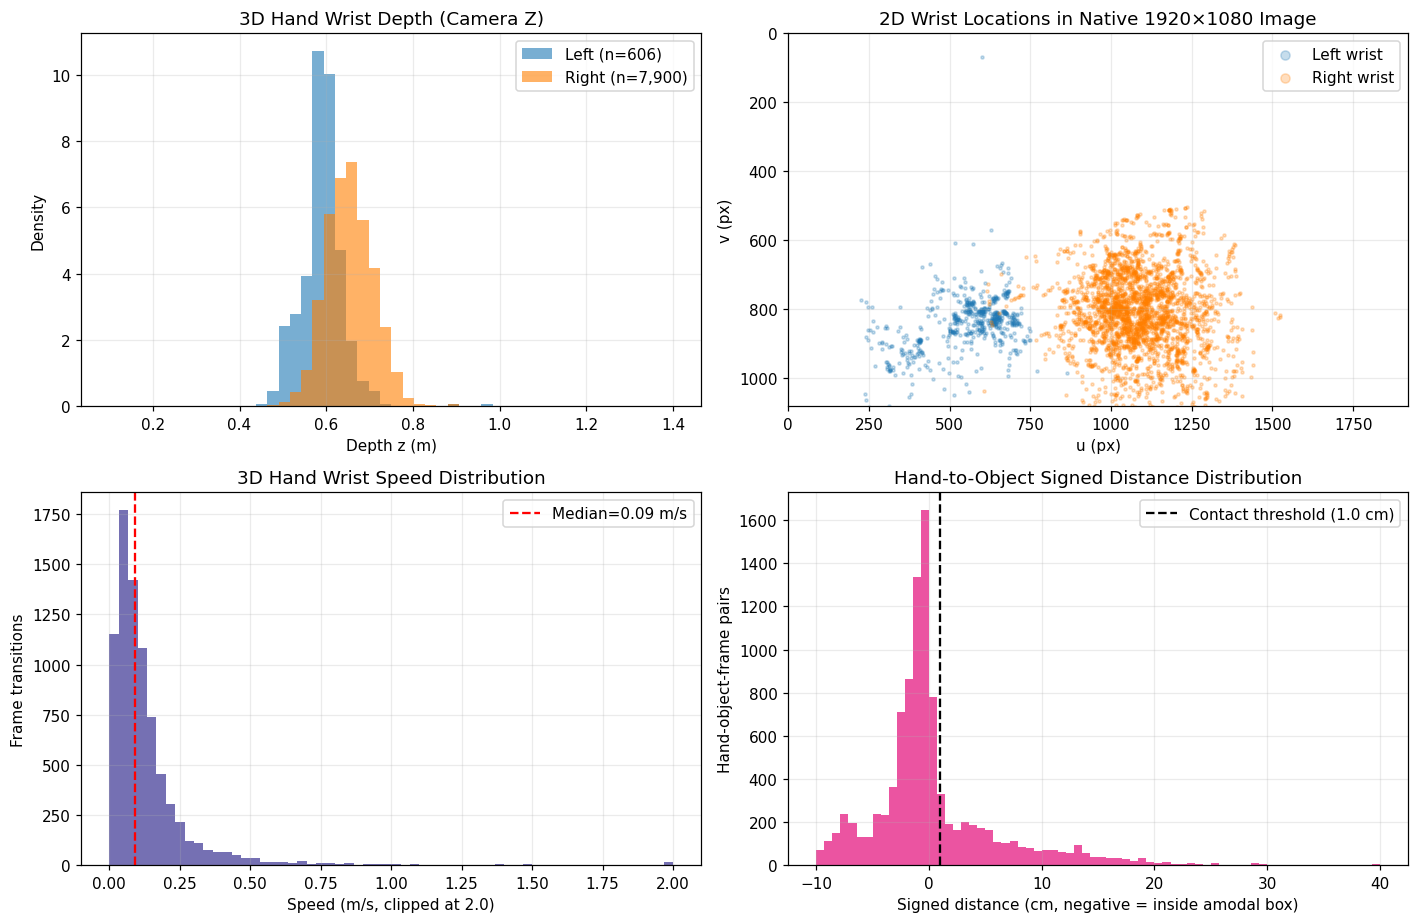

In [ ]:
w3_l = np.concatenate(hand_wrist_3d["left"]) if hand_wrist_3d["left"] else np.zeros((0, 3))
w3_r = np.concatenate(hand_wrist_3d["right"]) if hand_wrist_3d["right"] else np.zeros((0, 3))
w2_l = np.concatenate(hand_wrist_2d["left"]) if hand_wrist_2d["left"] else np.zeros((0, 2))
w2_r = np.concatenate(hand_wrist_2d["right"]) if hand_wrist_2d["right"] else np.zeros((0, 2))
spd_all = np.concatenate([*(hand_speed_3d["left"] or [np.zeros(0)]), *(hand_speed_3d["right"] or [np.zeros(0)])])
acc_all = np.concatenate([*(hand_accel_3d["left"] or [np.zeros(0)]), *(hand_accel_3d["right"] or [np.zeros(0)])])
cdist_all = np.concatenate(contact_dist_list) if contact_dist_list else np.zeros(0)
betas_all = np.concatenate(mano_betas_list) if mano_betas_list else np.zeros((0, 10))
pnorm_all = np.concatenate(mano_pose_norm_list) if mano_pose_norm_list else np.zeros(0)

hand_stats = pd.DataFrame([
    ("Left wrist depth z (m) [p5 / med / p95]", f"{np.percentile(w3_l[:,2], 5):.3f} / {np.median(w3_l[:,2]):.3f} / {np.percentile(w3_l[:,2], 95):.3f}" if len(w3_l) else "N/A"),
    ("Right wrist depth z (m) [p5 / med / p95]", f"{np.percentile(w3_r[:,2], 5):.3f} / {np.median(w3_r[:,2]):.3f} / {np.percentile(w3_r[:,2], 95):.3f}" if len(w3_r) else "N/A"),
    ("3D wrist speed (m/s) [med / p90 / p99]", f"{np.median(spd_all):.3f} / {np.percentile(spd_all, 90):.3f} / {np.percentile(spd_all, 99):.3f}" if len(spd_all) else "N/A"),
    ("3D wrist accel (m/s²) [med / p90]", f"{np.median(acc_all):.2f} / {np.percentile(acc_all, 90):.2f}" if len(acc_all) else "N/A"),
    ("MANO finger pose L2 norm [mean ± std]", f"{pnorm_all.mean():.3f} ± {pnorm_all.std():.3f}" if len(pnorm_all) else "N/A"),
    ("MANO betas std across dims 0..9 [min..max]", f"{betas_all.std(0).min():.3f} .. {betas_all.std(0).max():.3f}" if len(betas_all) else "N/A"),
    ("Contact signed dist (cm) [p10 / med / p90]", f"{np.percentile(cdist_all, 10)*100:.2f} / {np.median(cdist_all)*100:.2f} / {np.percentile(cdist_all, 90)*100:.2f}" if len(cdist_all) else "N/A"),
    ("Contact rate (dist < 1 cm)", f"{(cdist_all < 0.01).mean()*100:.1f}%" if len(cdist_all) else "N/A"),
], columns=["Hand / Contact Metric", "Value"])
display(hand_stats)

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))

# 1. 3D Wrist Depth Z
if len(w3_l):
    axes[0, 0].hist(w3_l[:, 2], bins=50, range=(0.1, 1.4), alpha=0.6, label=f"Left (n={len(w3_l):,})", color="#1f78b4", density=True)
if len(w3_r):
    axes[0, 0].hist(w3_r[:, 2], bins=50, range=(0.1, 1.4), alpha=0.6, label=f"Right (n={len(w3_r):,})", color="#ff7f00", density=True)
axes[0, 0].set_title("3D Hand Wrist Depth (Camera Z)")
axes[0, 0].set_xlabel("Depth z (m)")
axes[0, 0].set_ylabel("Density")
axes[0, 0].legend()

# 2. 2D Wrist Spatial Distribution (1920x1080)
if len(w2_l):
    sub_l = w2_l[np.random.default_rng(0).choice(len(w2_l), min(3000, len(w2_l)), replace=False)]
    axes[0, 1].scatter(sub_l[:, 0], sub_l[:, 1], s=4, alpha=0.25, color="#1f78b4", label="Left wrist")
if len(w2_r):
    sub_r = w2_r[np.random.default_rng(1).choice(len(w2_r), min(3000, len(w2_r)), replace=False)]
    axes[0, 1].scatter(sub_r[:, 0], sub_r[:, 1], s=4, alpha=0.25, color="#ff7f00", label="Right wrist")
axes[0, 1].set_xlim(0, 1920)
axes[0, 1].set_ylim(1080, 0)
axes[0, 1].set_title("2D Wrist Locations in Native 1920×1080 Image")
axes[0, 1].set_xlabel("u (px)")
axes[0, 1].set_ylabel("v (px)")
axes[0, 1].legend(markerscale=3)

# 3. 3D Wrist Speed
if len(spd_all):
    axes[1, 0].hist(np.clip(spd_all, 0, 2.0), bins=60, color="#7570b3")
    axes[1, 0].axvline(np.median(spd_all), color="red", ls="--", label=f"Median={np.median(spd_all):.2f} m/s")
    axes[1, 0].set_title("3D Hand Wrist Speed Distribution")
    axes[1, 0].set_xlabel("Speed (m/s, clipped at 2.0)")
    axes[1, 0].set_ylabel("Frame transitions")
    axes[1, 0].legend()

# 4. Signed Contact Distance
if len(cdist_all):
    axes[1, 1].hist(np.clip(cdist_all * 100, -10, 40), bins=70, color="#e7298a", alpha=0.8)
    axes[1, 1].axvline(1.0, color="black", ls="--", lw=1.5, label="Contact threshold (1.0 cm)")
    axes[1, 1].set_title("Hand-to-Object Signed Distance Distribution")
    axes[1, 1].set_xlabel("Signed distance (cm, negative = inside amodal box)")
    axes[1, 1].set_ylabel("Hand-object-frame pairs")
    axes[1, 1].legend()

plt.tight_layout()
plt.show()

## 5. 6-DoF Object Geometry, Camera Intrinsics & Ego-Camera Motion

Camera Intrinsics K by Device (native 1920×1080):


fx             fy            cx            cy      
                  mean count     mean count    mean count    mean count
device                                                                 
ZY20210800001  1060.30   393  1061.51   393  971.52   393  523.26   393
ZY20210800002  1081.09   295  1083.11   295  946.31   295  526.07   295
ZY20210800003  1079.19   207  1082.61   207  952.03   207  531.14   207
ZY20210800004  1077.68   305  1074.95   305  960.15   305  540.33   305


Object 3D Box Extents by Category (median metres & volume in litres):


,l,w,h,vol_L
category,,,,
Chair,0.379,0.355,0.510,67.224
StorageFurniture,0.343,0.371,0.374,14.875
Kettle,0.219,0.158,0.239,8.187
Bucket,0.282,0.120,0.192,5.112
Safe,0.088,0.124,0.184,2.513
TrashCan,0.158,0.158,0.115,2.394
Bowl,0.137,0.131,0.070,1.180
Laptop,0.227,0.330,0.015,1.095
Mug,0.122,0.085,0.094,0.980


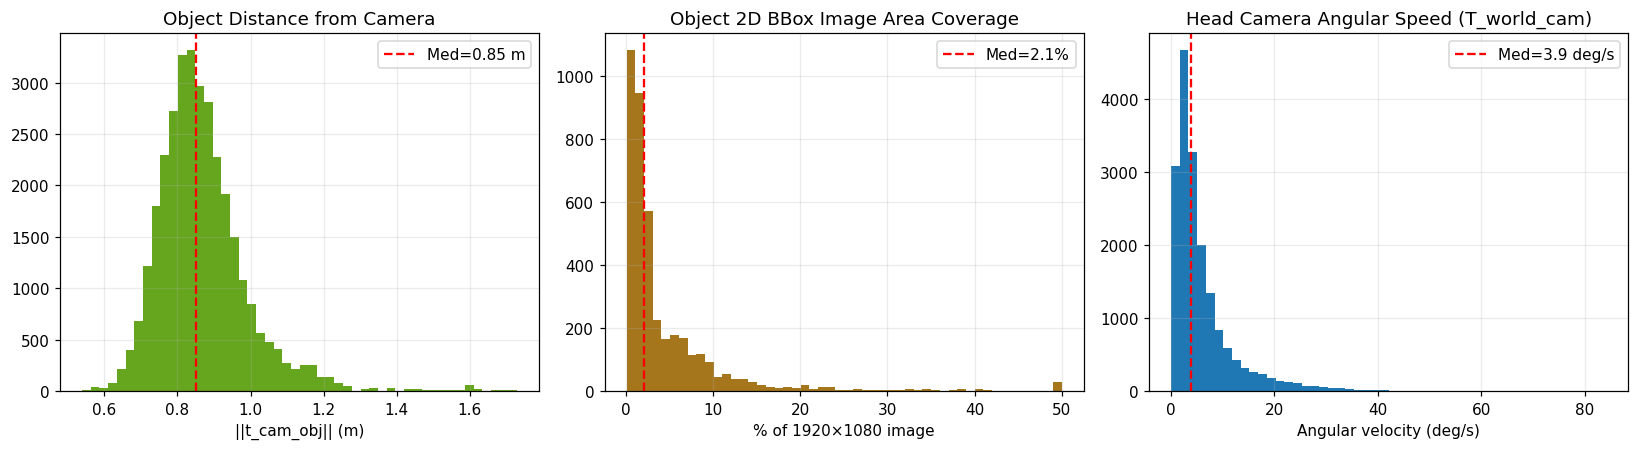

In [ ]:
odf = pd.DataFrame(obj_dims_rows)
obj_dist = np.concatenate(obj_dist_list) if obj_dist_list else np.zeros(0)
obj_area = np.concatenate(obj_area_frac_list) if obj_area_frac_list else np.zeros(0)
cam_v = np.concatenate(cam_lin_speed) if cam_lin_speed else np.zeros(0)
cam_w = np.concatenate(cam_ang_speed) if cam_ang_speed else np.zeros(0)

kdf = pd.DataFrame(intrinsics_rows).groupby("device").agg(["mean", "count"])
print("Camera Intrinsics K by Device (native 1920×1080):")
display(kdf.round(2))

print("\nObject 3D Box Extents by Category (median metres & volume in litres):")
cat_dims = odf.groupby("category")[["l", "w", "h", "vol_L"]].median().sort_values("vol_L", ascending=False)
display(cat_dims.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].hist(np.clip(obj_dist, 0, 2.5), bins=50, color="#66a61e")
axes[0].axvline(np.median(obj_dist), color="red", ls="--", label=f"Med={np.median(obj_dist):.2f} m")
axes[0].set_title("Object Distance from Camera")
axes[0].set_xlabel("||t_cam_obj|| (m)")
axes[0].legend()

axes[1].hist(np.clip(obj_area * 100, 0, 50), bins=50, color="#a6761d")
axes[1].axvline(np.median(obj_area) * 100, color="red", ls="--", label=f"Med={np.median(obj_area)*100:.1f}%")
axes[1].set_title("Object 2D BBox Image Area Coverage")
axes[1].set_xlabel("% of 1920×1080 image")
axes[1].legend()

axes[2].hist(np.clip(cam_w, 0, 90), bins=50, color="#1f78b4")
axes[2].axvline(np.median(cam_w), color="red", ls="--", label=f"Med={np.median(cam_w):.1f} deg/s")
axes[2].set_title("Head Camera Angular Speed (T_world_cam)")
axes[2].set_xlabel("Angular velocity (deg/s)")
axes[2].legend()

plt.tight_layout()
plt.show()

## 6. Pass 2 — Dense Multimodal `DataLoader` (RGB, Metric Depth, 2D Seg, Scene Cloud & CAD Meshes)

Now we instantiate a second `DataLoader` with the exact training transform (`resize=256`, `center_crop=[256, 256]`) and all HOI4D dense & 3D surface modalities enabled (`rgb`, `depth`, `seg`, `scene`, `mesh`, `contact`).

,Dense / 3D Modality Metric,Value
0,Pass 2 runtime / clips,36.8s / 96 clips
1,"RGB channel mean (R, G, B)","(0.551, 0.536, 0.515)"
2,"RGB channel std (R, G, B)","(0.212, 0.227, 0.250)"
3,Depth valid pixel ratio (depth > 0),96.93%
4,Depth metres [p5 / med / p95],0.65 / 0.96 / 1.65 m
5,Scene cloud valid rate & median bbox (m),"100.0% | [2.3499999046325684, 1.51999998092651..."
6,CAD mesh coverage on active objects,152/152 (100.0%)
7,CAD surface normal unit-length mean error,2.23e-08


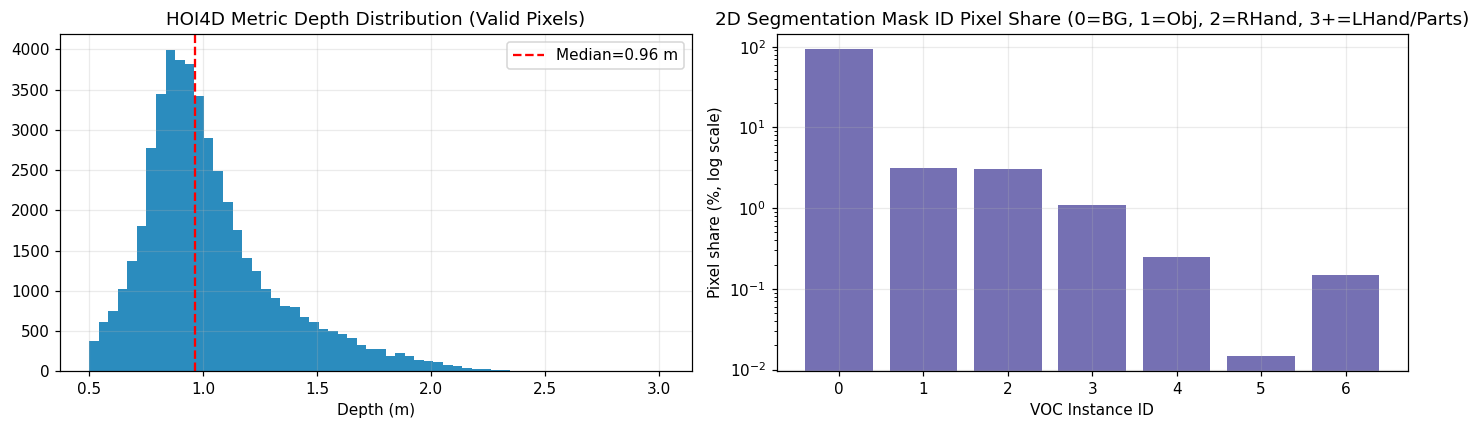

In [ ]:
cfg_pass2 = {
    "clip_len": 4,
    "fps": 5,
    "max_objects": 6,
    "scene_points": 4096,
    "mesh_points": 1024,
    "modalities": ["rgb", "depth", "seg", "scene", "mesh", "contact"],
    "transforms": {"resize": 256, "center_crop": [256, 256]},
    "sources": [
        {
            "dataset": "hoi4d",
            "sampling": "sliding",
            "stride_s": 6.0,
        }
    ],
}

t0 = time.time()
dl_p2, _ = make_loader(cfg_pass2, PASS2_MAX_CLIPS, BATCH_SIZE_P2, seed=SEED + 1)

rgb_sum = np.zeros(3, np.float64)
rgb_sq = np.zeros(3, np.float64)
rgb_n = 0
depth_samples = []
depth_valid_px = 0
depth_total_px = 0
seg_hist = Counter()
scene_valid_cnt = 0
scene_span_list = []
mesh_valid_objs = 0
mesh_total_objs = 0
mesh_norm_err = []
vis_samples = []

for batch in dl_p2:
    frames = batch["frames"].numpy()          # (B, T, 3, H, W) float [0, 1]
    depth = batch["depth"].numpy()            # (B, T, 1, H, W) metres
    d_val = batch["depth_valid"].numpy()
    seg = batch["seg"].numpy()                # (B, T, H, W) uint8
    s_val = batch["seg_valid"].numpy()
    sc = batch["scene_points"].numpy()        # (B, N, 6)
    sc_val = batch["scene_valid"].numpy()
    op = batch["object_points"].numpy()       # (B, O, P, 6)
    op_val = batch["object_points_valid"].numpy()
    ov = batch["obj_valid"].numpy()

    B, T = frames.shape[:2]
    rgb_sum += frames.sum(axis=(0, 1, 3, 4))
    rgb_sq += (frames ** 2).sum(axis=(0, 1, 3, 4))
    rgb_n += B * T * frames.shape[3] * frames.shape[4]

    for b in range(B):
        if d_val[b]:
            d = depth[b]
            pos = d > 0
            depth_valid_px += int(pos.sum())
            depth_total_px += int(d.size)
            if pos.any():
                vals = d[pos]
                depth_samples.append(vals[::max(1, len(vals) // 500)])
        if s_val[b]:
            u, c = np.unique(seg[b], return_counts=True)
            for ui, ci in zip(u.tolist(), c.tolist()):
                seg_hist[ui] += ci
        if sc_val[b]:
            scene_valid_cnt += 1
            xyz = sc[b, :, :3]
            scene_span_list.append(xyz.max(0) - xyz.min(0))
        n_active = int(ov[b].any(axis=1).sum())
        mesh_total_objs += n_active
        mesh_valid_objs += int(op_val[b].sum())
        for o in np.flatnonzero(op_val[b]):
            nrm = np.linalg.norm(op[b, o, :, 3:], axis=-1)
            mesh_norm_err.append(float(np.abs(nrm - 1.0).mean()))

        # Grab a few clips with visible hands for visualization
        if len(vis_samples) < 4 and batch["hand_valid"][b].any() and d_val[b] and s_val[b]:
            vis_samples.append({
                "seq_id": batch["sequence_id"][b],
                "action": batch["action"][b],
                "rgb": np.transpose(frames[b, 0], (1, 2, 0)),
                "depth": depth[b, 0, 0],
                "seg": seg[b, 0],
                "h2d": batch["hand_joints_2d"][b, :, 0].numpy(),
                "hv": batch["hand_valid"][b, :, 0].numpy(),
                "obox": batch["obj_bbox_2d"][b, :, 0].numpy(),
                "ov": ov[b, :, 0],
                "contact": bool((batch["contact"][b, :, :, 0] & batch["contact_valid"][b, :, :, 0]).any()),
            })

rgb_mean = rgb_sum / rgb_n
rgb_std = np.sqrt(np.maximum(rgb_sq / rgb_n - rgb_mean ** 2, 0.0))
d_arr = np.concatenate(depth_samples) if depth_samples else np.zeros(0)
sc_spans = np.array(scene_span_list) if scene_span_list else np.zeros((0, 3))

dense_summary = pd.DataFrame([
    ("Pass 2 runtime / clips", f"{time.time() - t0:.1f}s / {len(dl_p2.dataset)} clips"),
    ("RGB channel mean (R, G, B)", f"({rgb_mean[0]:.3f}, {rgb_mean[1]:.3f}, {rgb_mean[2]:.3f})"),
    ("RGB channel std (R, G, B)", f"({rgb_std[0]:.3f}, {rgb_std[1]:.3f}, {rgb_std[2]:.3f})"),
    ("Depth valid pixel ratio (depth > 0)", f"{100.0 * depth_valid_px / max(depth_total_px, 1):.2f}%"),
    ("Depth metres [p5 / med / p95]", f"{np.percentile(d_arr, 5):.2f} / {np.median(d_arr):.2f} / {np.percentile(d_arr, 95):.2f} m"),
    ("Scene cloud valid rate & median bbox (m)", f"{100.0 * scene_valid_cnt / len(dl_p2.dataset):.1f}% | {np.median(sc_spans, 0).round(2).tolist()}"),
    ("CAD mesh coverage on active objects", f"{mesh_valid_objs}/{mesh_total_objs} ({100.0 * mesh_valid_objs / max(mesh_total_objs, 1):.1f}%)"),
    ("CAD surface normal unit-length mean error", f"{np.mean(mesh_norm_err):.2e}" if mesh_norm_err else "N/A"),
], columns=["Dense / 3D Modality Metric", "Value"])
display(dense_summary)

# Depth histogram + Seg pixel occupancy
fig, axes = plt.subplots(1, 2, figsize=(13, 4.0))
axes[0].hist(np.clip(d_arr, 0, 3.5), bins=60, color="#2b8cbe")
axes[0].axvline(np.median(d_arr), color="red", ls="--", label=f"Median={np.median(d_arr):.2f} m")
axes[0].set_title("HOI4D Metric Depth Distribution (Valid Pixels)")
axes[0].set_xlabel("Depth (m)")
axes[0].legend()

tot_px = sum(seg_hist.values())
seg_ids = sorted(k for k in seg_hist if seg_hist[k] / tot_px > 1e-4)[:10]
seg_pcts = [100.0 * seg_hist[k] / tot_px for k in seg_ids]
axes[1].bar([str(k) for k in seg_ids], seg_pcts, color="#7570b3")
axes[1].set_yscale("log")
axes[1].set_title("2D Segmentation Mask ID Pixel Share (0=BG, 1=Obj, 2=RHand, 3+=LHand/Parts)")
axes[1].set_xlabel("VOC Instance ID")
axes[1].set_ylabel("Pixel share (%, log scale)")
plt.tight_layout()
plt.show()

## 7. Visual Sanity Check Directly from `DataLoader` Batch Tensors

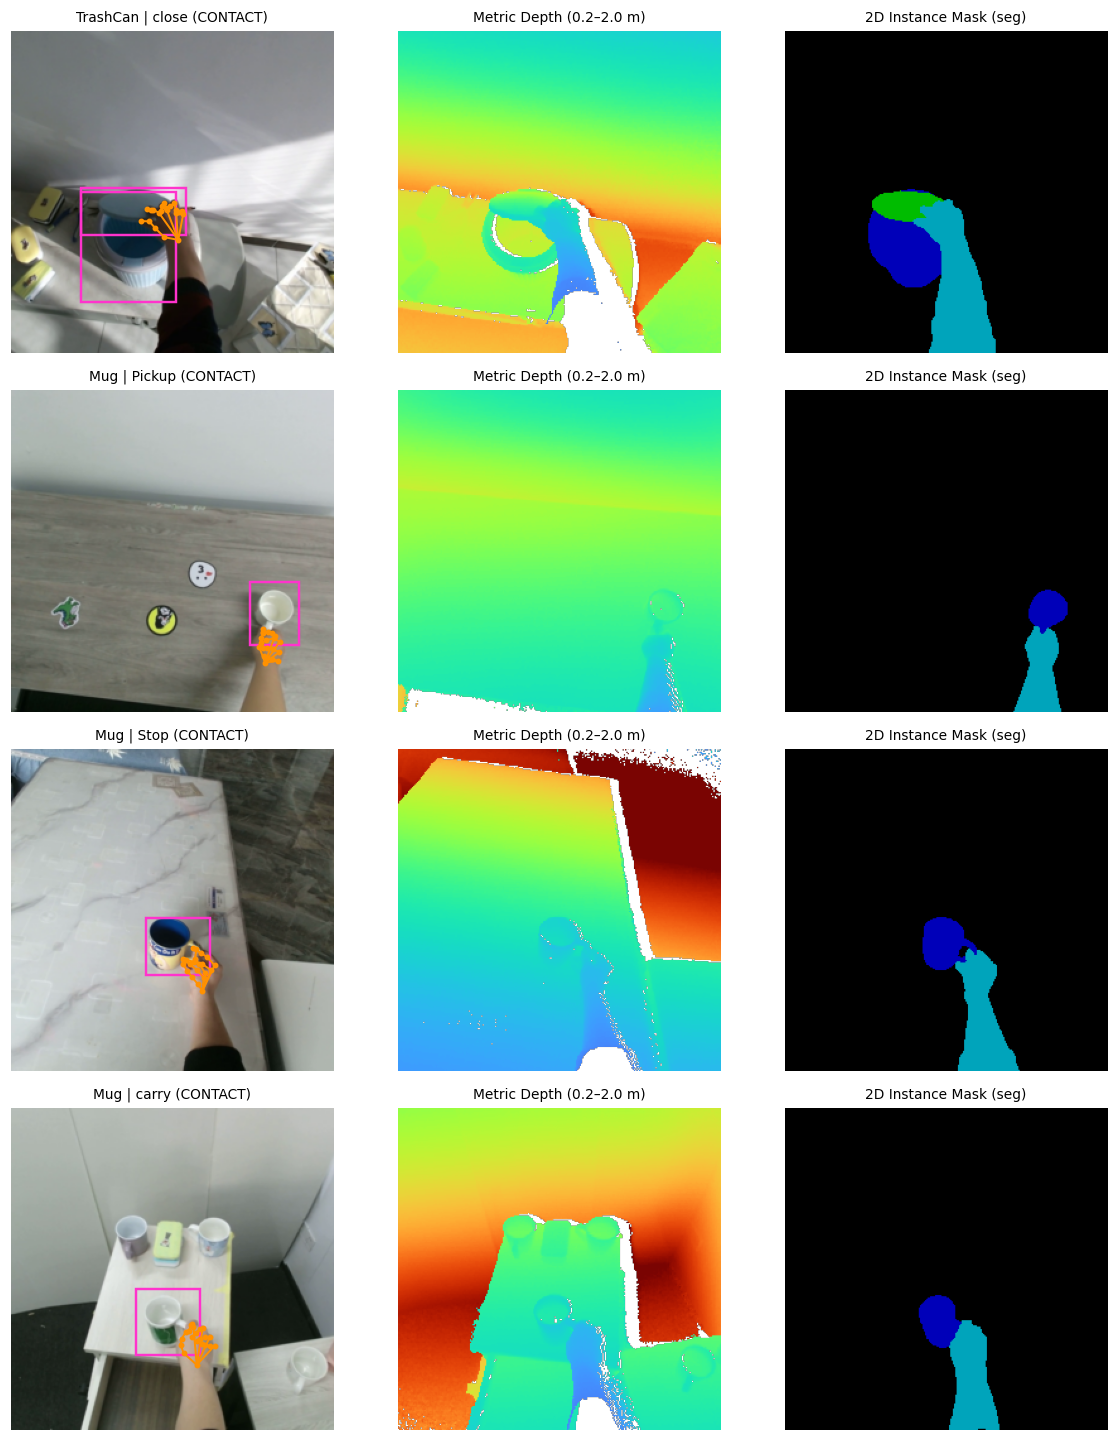

In [ ]:
if vis_samples:
    fig, axes = plt.subplots(len(vis_samples), 3, figsize=(11, 3.3 * len(vis_samples)))
    if len(vis_samples) == 1:
        axes = axes[None, :]
    for row, s in enumerate(vis_samples):
        # Col 0: RGB + 2D hand skeletons + object boxes
        ax = axes[row, 0]
        ax.imshow(s["rgb"])
        for o in np.flatnonzero(s["ov"]):
            x0, y0, x1, y1 = s["obox"][o]
            ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="#ff33cc" if s["contact"] else "#00ff88", lw=1.6))
        for side_i, col in ((0, "#00e5ff"), (1, "#ff9100")):
            if s["hv"][side_i]:
                pts = s["h2d"][side_i]
                for j, p in enumerate(HAND_PARENTS):
                    if p >= 0:
                        ax.plot([pts[p, 0], pts[j, 0]], [pts[p, 1], pts[j, 1]], color=col, lw=1.3)
                ax.scatter(pts[:, 0], pts[:, 1], s=8, color=col)
        tag = "CONTACT" if s["contact"] else "no-contact"
        ax.set_title(f"{parse_hoi4d_id(s['seq_id'])['category']} | {s['action']} ({tag})", fontsize=9)
        ax.axis("off")

        # Col 1: Metric Depth
        im = axes[row, 1].imshow(np.where(s["depth"] > 0, s["depth"], np.nan), cmap="turbo", vmin=0.2, vmax=2.0)
        axes[row, 1].set_title("Metric Depth (0.2–2.0 m)", fontsize=9)
        axes[row, 1].axis("off")

        # Col 2: Segmentation mask
        axes[row, 2].imshow(s["seg"], cmap="nipy_spectral", vmin=0, vmax=6)
        axes[row, 2].set_title("2D Instance Mask (seg)", fontsize=9)
        axes[row, 2].axis("off")
    plt.tight_layout()
    plt.show()